In [1]:
#Import relevant libraries
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_csv("C:/Users/akul9/Courses/ml-zoomcamp/data/car_fuel_efficiency_2026.csv")

We shall first do some exploration of the dataset

In [3]:
print(df.dtypes)
df.head()

model_year               int64
origin                     str
fuel_type                  str
drivetrain                 str
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object


,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


Ok the column names seem to be all lowercase and python-variable friendly. However the columns that have "string" values need to be fixed 

In [4]:
strings = list(df.dtypes[df.dtypes == 'str'].index) #get all strings from your dataset

for s in strings:
    df[s] = df[s].str.lower().str.replace(' ', '_').str.replace('-', '_')

df

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,europe,gasoline,front_wheel_drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,europe,diesel,front_wheel_drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,asia,gasoline,front_wheel_drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,europe,gasoline,front_wheel_drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,usa,diesel,front_wheel_drive,3,2580,7,304.0,4510,17.5,31.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2005,usa,gasoline,all_wheel_drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,asia,gasoline,all_wheel_drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,usa,gasoline,all_wheel_drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,usa,hybrid,rear_wheel_drive,5,2180,6,270.0,4450,20.9,32.2


In [5]:
cols = ['engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']

df_homework = df[cols]
df_homework

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

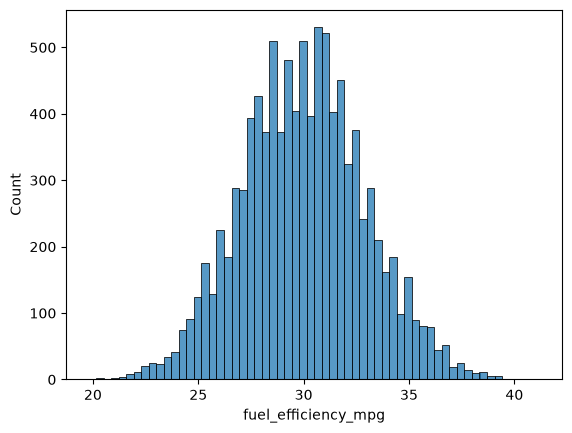

In [6]:
#Look at the fuel_efficiency_mpg variable. Does it have a long tail?
sns.histplot(df_homework['fuel_efficiency_mpg'])

#Answer - no, it is normally distributed

In [7]:
#There's one column with missing values. What is it?
df_homework.isnull().sum()

#Answer - horsepower

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [8]:
#What's the median (50% percentile) for variable 'horsepower'?
df_homework['horsepower'].median()

#Answer - 254

np.float64(254.0)

Ok the lesson we learn is to use pandas built-in functions, or numpy's nanmean functions that automatically deals with missing values

Next we need to split the dataset into train, validate and test. I assume we will go with a 60 - 20 - 20 split. So here are the steps. 

1. Shuffle the dataset, so that all unique values are present in each dataset
2. From the shuffled dataset, pick the rows into training, validation, and test datasets in a 60/20/20 ration
3. Find the outcome variable column, save it in a new y_pred variable and remove that column from the dataset so that it is not treated as a feature


In [9]:
#1. Shuffle the dataset
np.random.seed(42)

idx = list(df_homework.index)

np.random.shuffle(idx)

df_shuffled = df_homework.iloc[idx].reset_index(drop=True) 
print(df_shuffled.head())
print(df_homework.head())


   engine_displacement  horsepower  vehicle_weight  model_year  \
0                 1900       239.0            3790        2015   
1                 2000       224.0            4380        1992   
2                 2330       286.0            4090        2022   
3                 2300         NaN            4150        1997   
4                 2340       269.0            4400        2001   

   fuel_efficiency_mpg  
0                 32.5  
1                 29.1  
2                 34.1  
3                 30.6  
4                 30.7  
   engine_displacement  horsepower  vehicle_weight  model_year  \
0                 2180       243.0            3870        2006   
1                 2390       272.0            4210        2008   
2                 2320       267.0            4240        1996   
3                 2130       258.0            4490        1989   
4                 2580       304.0            4510        1994   

   fuel_efficiency_mpg  
0                 31.9  
1     

In [10]:
#2. From the shuffled dataset, pick the rows into training, validation, and test datasets in a 60/20/20 ration

n = len(idx)

n_train = int(n*0.6)
n_val   = int(n*0.2)
n_test  = int(n*0.2)

print(n_train, n_val, n_test)

df_train = df_shuffled.iloc[:n_train]
df_val   = df_shuffled.iloc[n_train:n_train+n_val]
df_test  = df_shuffled.iloc[n_train+n_val:]



6000 2000 2000


In [11]:
#3. Find the outcome variable column, save it in a new y_pred variable and remove that column from the dataset so that it is not treated as a feature
y_train = df_train['fuel_efficiency_mpg']
del df_train['fuel_efficiency_mpg']

y_val = df_val['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']

y_test = df_test['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

Question 3

    We need to deal with missing values for the column from Q1.
    We have two options: fill it with 0 or with the mean of this variable.
    Try both options. For each, train a linear regression model without regularization using the code from the lessons.
    For computing the mean, use the training only!
    Use the validation dataset to evaluate the models and compare the RMSE of each option.
    Round the RMSE scores to 3 decimal digits using round(score, 3). This keeps the imputation difference visible in this release.
    Which option gives better RMSE?

Options:

    With 0
    With mean
    Both are equally good


Ok so we need to fit the linear regression model without regularisation, and then validate the model using RMSE. We need to train the model with two dataset types - filling missing values with 0s, or filling them with the mean of that column. Let us try doing fillna(0) first. 

Step 1. Fill all missing values in horsepower with 0, for the whole dataset (?) or just for training (?). 
Step 2. Since the feature matrix are all continuous variables, we can fit the regression model as it is without changing much. Use the function to do this
Step 3. Prepare the validation dataset in the same way and then calculate RMSE

In [12]:
#Step 2. Since the feature matrix are all continuous variables, we can fit the regression model as it is without changing much. Use the function to do this

#Define the train linear regression function
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)

    w_full = XTX_inv.dot(X.T).dot(y)
    w0 = w_full[0]
    w  = w_full[1:]

    return w0, w

#Prepare feature matrix by filling with 0
def prepare_X(df, base):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

#Find the RMSE
def rmse(y, y_pred):
    sq_error = np.square(y_pred - y) #Error term is the difference between true and predicted, and then you square them
    mse = sq_error.mean() #You get the mean squared error
    rmse = np.sqrt(mse) #then you square root them
    rmse = rmse
    return rmse

In [13]:
#Train your model
base = df_train.columns
X_train = prepare_X(df_train, base)
w0, w = train_linear_regression(X_train, y_train)

In [14]:
#Validate your model using X_validate and use y_val and y_pred for RMSE
base = df_val.columns
X_val = prepare_X(df_val, base)

y_pred = w0 + X_val.dot(w)

rmse_0 = rmse(y_val, y_pred)

rmse_0

np.float64(2.20529319475341)

Ok we got 2.2057 when we fill with 0. Let us try by using the mean

In [15]:
#Prepare feature matrix by filling with mean of training dataset horsepower
mean_hp = df_train['horsepower'].mean()

def prepare_X_mean(df, base):
    df_num = df[base]
    df_num = df_num.fillna(mean_hp)
    X = df_num.values
    return X

In [16]:
#Train your model
base = df_train.columns
X_train = prepare_X_mean(df_train, base)
w0, w = train_linear_regression(X_train, y_train)

#Validate your model using X_validate and use y_val and y_pred for RMSE
base = df_val.columns
X_val = prepare_X_mean(df_val, base)

y_pred = w0 + X_val.dot(w)

rmse_mean = rmse(y_val, y_pred)


In [17]:
#Which option gives better RMSE?

print(f"The rmse value when filling missing with 0 is: {round(rmse_0, 3)}, whereas the rmse value when filling missing with the mean is: {round(rmse_mean, 3)}")


The rmse value when filling missing with 0 is: 2.205, whereas the rmse value when filling missing with the mean is: 2.202


Question 4

    Now let's train a regularized linear regression.
    For this question, fill the NAs with 0.
    Try different values of r from this list: [0, 0.01, 0.1, 1, 5, 10, 100].
    Use RMSE to evaluate the model on the validation dataset.
    Round the RMSE scores to 4 decimal digits. This keeps the small but real regularization differences visible instead of turning several choices into a tie.
    Which r gives the best RMSE?

If multiple options give the same best RMSE, select the smallest r.

In [18]:
#Step 1. Let's add a regularisation term to the linear regression function
#Define the train linear regression function
def train_linear_regression(X, y, r):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r*np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)

    w_full = XTX_inv.dot(X.T).dot(y)
    w0 = w_full[0]
    w  = w_full[1:]

    return w0, w


In [19]:
base = df_train.columns
X_train = prepare_X(df_train, base)
X_val = prepare_X(df_val, base)

r_values = [0, 0.01, 0.1, 1, 5, 10, 100]

for r in r_values:
    #Train your model
    w0, w = train_linear_regression(X_train, y_train, r)

    #Validate your model using X_validate and use y_val and y_pred for RMSE
    base = df_val.columns

    y_pred = w0 + X_val.dot(w)

    rmse_score = rmse(y_val, y_pred)
    print(r, w0, rmse_score)

#Answer: r = 0 has the lowest rmse    

0 -153.8849618823138 2.20529319475341
0.01 -148.3092124404723 2.2058276166720066
0.1 -111.83871039306318 2.2241432777850454
1 -32.331865964971264 2.3492288883928363
5 -7.7728522099734025 2.40938016659955
10 -3.9871164160193766 2.419469865473249
100 -0.40821964884790385 2.429202138016282


Question 5

    We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
    Try different seed values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9].
    For each seed, do the train/validation/test split with 60%/20%/20% distribution.
    Fill the missing values with 0 and train a model without regularization.
    For each seed, evaluate the model on the validation dataset and collect the RMSE scores.
    What's the standard deviation of all the scores? To compute the standard deviation, use np.std.
    Round the result to 3 decimal digits (round(std, 3))


In [20]:
#Step 2. Since the feature matrix are all continuous variables, we can fit the regression model as it is without changing much. Use the function to do this

#Define the train linear regression function
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)

    w_full = XTX_inv.dot(X.T).dot(y)
    w0 = w_full[0]
    w  = w_full[1:]

    return w0, w

#Prepare feature matrix by filling with 0
def prepare_X(df, base):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

#Find the RMSE
def rmse(y, y_pred):
    sq_error = np.square(y_pred - y) #Error term is the difference between true and predicted, and then you square them
    mse = sq_error.mean() #You get the mean squared error
    rmse = np.sqrt(mse) #then you square root them
    rmse = rmse
    return rmse

In [21]:
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
rmse_vals = np.zeros(len(seeds))
for s in seeds:
    #1. Shuffle the dataset
    np.random.seed(s)

    idx = list(df_homework.index)

    np.random.shuffle(idx)

    df_shuffled = df_homework.iloc[idx].reset_index(drop=True) 

    #2. From the shuffled dataset, pick the rows into training, validation, and test datasets in a 60/20/20 ration

    n = len(idx)

    n_train = int(n*0.6)
    n_val   = int(n*0.2)
    n_test  = int(n*0.2)

    df_train = df_shuffled.iloc[:n_train]
    df_val   = df_shuffled.iloc[n_train:n_train+n_val]
    df_test  = df_shuffled.iloc[n_train+n_val:]

    #3. Find the outcome variable column, save it in a new y_pred variable and remove that column from the dataset so that it is not treated as a feature
    y_train = df_train['fuel_efficiency_mpg']
    del df_train['fuel_efficiency_mpg']

    y_val = df_val['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']

    y_test = df_test['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    #Train your model
    base = df_train.columns
    X_train = prepare_X(df_train, base)
    w0, w = train_linear_regression(X_train, y_train)

    #Validate your model using X_validate and use y_val and y_pred for RMSE
    base = df_val.columns
    X_val = prepare_X(df_val, base)

    y_pred = w0 + X_val.dot(w)

    rmse_score = rmse(y_val, y_pred)

    rmse_vals[s] = rmse_score


#Find the standard deviation
round(np.std(rmse_vals),3)  

#Answer .029


np.float64(0.029)

Question 6

    Split the dataset like previously, use seed 9.
    Combine train and validation datasets.
    Fill the missing values with 0 and train a model with r=0.001.
    What's the RMSE on the test dataset?


In [22]:
#1. Split dataset using seed 9
np.random.seed(9)

idx = list(df_homework.index)

np.random.shuffle(idx)

df_shuffled = df_homework.iloc[idx].reset_index(drop=True) 

#2. From the shuffled dataset, pick the rows into training, validation, and test datasets in a 60/20/20 ration

n = len(idx)

n_train = int(n*0.6)
n_val   = int(n*0.2)
n_test  = int(n*0.2)

df_train = df_shuffled.iloc[:n_train]
df_val   = df_shuffled.iloc[n_train:n_train+n_val]
df_test  = df_shuffled.iloc[n_train+n_val:]

#3. Find the outcome variable column, save it in a new y_pred variable and remove that column from the dataset so that it is not treated as a feature
y_train = df_train['fuel_efficiency_mpg']
del df_train['fuel_efficiency_mpg']

y_val = df_val['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']

y_test = df_test['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']


In [23]:
#2. Combine train and validation datasets

df_train_full =  pd.concat([df_train, df_val]).reset_index(drop = True)
y_train_full  =  np.concat([y_train, y_val])


In [24]:
#Define the train linear regression function with regularisation term
def train_linear_regression(X, y, r):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r*np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)

    w_full = XTX_inv.dot(X.T).dot(y)
    w0 = w_full[0]
    w  = w_full[1:]

    return w0, w

In [25]:
#Fill with 0 and train with full dataset, and test with test dataset
base = df_train_full.columns
X_train_full = prepare_X(df_train_full, base)
w0, w = train_linear_regression(X_train_full, y_train_full, r = .001)

X_test       = prepare_X(df_test, base)
y_pred       = w0 + X_test.dot(w)

rmse(y_pred, y_test)

#Answer = 2.236

np.float64(2.235827747191731)